# House Price Prediction
Machine Learning project using Decision Tree and Random Forest regression models.

Dataset: `housing data.csv` (1,418 rows, 13 columns). Target: `SalePrice`.


## 1. Import libraries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score


## 2. Load and inspect the dataset


In [ ]:
df = pd.read_csv('housing data.csv')
print('Dataset shape:', df.shape)
display(df.head())
display(df.info())
display(df.isnull().sum().sort_values(ascending=False))


Dataset shape: (1418, 13)


,Id,OverallQual,YearBuilt,TotalBsmtSF,Electrical,GrLivArea,FullBath,GarageType,GarageCars,GarageArea,Fence,MiscFeature,SalePrice
0,1,7,2003,856,SBrkr,1710,2,Attchd,2,548,NaN,NaN,208500
1,2,6,1976,1262,SBrkr,1262,2,Attchd,2,460,NaN,NaN,181500
2,3,7,2001,920,SBrkr,1786,2,Attchd,2,608,NaN,NaN,223500
3,4,7,1915,756,SBrkr,1717,1,Detchd,3,642,NaN,NaN,140000
4,5,8,2000,1145,SBrkr,2198,2,Attchd,3,836,NaN,NaN,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1418 entries, 0 to 1417
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Id           1418 non-null   int64 
 1   OverallQual  1418 non-null   int64 
 2   YearBuilt    1418 non-null   int64 
 3   TotalBsmtSF  1418 non-null   int64 
 4   Electrical   1417 non-null   object
 5   GrLivArea    1418 non-null   int64 
 6   FullBath     1418 non-null   int64 
 7   GarageType   1275 non-null   object
 8   GarageCars   1418 non-null   int64 
 9   GarageArea   1418 non-null   int64 
 10  Fence        270 non-null    object
 11  MiscFeature  52 non-null     object
 12  SalePrice    1418 non-null   int64 
dtypes: int64(9), object(4)
memory usage: 144.1+ KB


None

MiscFeature    1366
Fence          1148
GarageType      143
Electrical        1
Id                0
OverallQual       0
YearBuilt         0
TotalBsmtSF       0
GrLivArea         0
FullBath          0
GarageCars        0
GarageArea        0
SalePrice         0
dtype: int64

## 3. Prepare features and target
`Id` is an identifier, so it is excluded from model training. `SalePrice` is the value to predict.


In [ ]:
X = df.drop(columns=['SalePrice', 'Id'])
y = df['SalePrice']

numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(exclude=['number']).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Training rows:', X_train.shape[0])
print('Validation rows:', X_valid.shape[0])


Training rows: 1134
Validation rows: 284


## 4. Decision Tree model


In [ ]:
tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(random_state=42, max_leaf_nodes=100))
])
tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_valid)
tree_mae = mean_absolute_error(y_valid, tree_predictions)
print(f'Decision Tree MAE: ${tree_mae:,.2f}')
print(f'Decision Tree R2: {r2_score(y_valid, tree_predictions):.3f}')


Decision Tree MAE: $21,599.41
Decision Tree R2: 0.847


## 5. Random Forest model


In [ ]:
forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))
])
forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_valid)
forest_mae = mean_absolute_error(y_valid, forest_predictions)
print(f'Random Forest MAE: ${forest_mae:,.2f}')
print(f'Random Forest R2: {r2_score(y_valid, forest_predictions):.3f}')


Random Forest MAE: $19,803.99
Random Forest R2: 0.860


## 6. Compare models


In [ ]:
results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'MAE': [tree_mae, forest_mae],
    'R2': [
        r2_score(y_valid, tree_predictions),
        r2_score(y_valid, forest_predictions)
    ]
})

display(results.sort_values('MAE'))


,Model,MAE,R2
1,Random Forest,19803.994863,0.860032
0,Decision Tree,21599.408635,0.846971


## 7. Tune Decision Tree leaf nodes


In [ ]:
leaf_options = [10, 25, 50, 100, 200, 500]
tuning_results = []
for leaf_count in leaf_options:
    candidate = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeRegressor(random_state=42, max_leaf_nodes=leaf_count))
    ])
    candidate.fit(X_train, y_train)
    pred = candidate.predict(X_valid)
    tuning_results.append({
        'max_leaf_nodes': leaf_count,
        'MAE': mean_absolute_error(y_valid, pred)
    })
tuning_df = pd.DataFrame(tuning_results).sort_values('MAE')
display(tuning_df)


,max_leaf_nodes,MAE
2,50,20134.401550
3,100,21599.408635
1,25,22502.437997
4,200,23290.169655
5,500,25800.729661
0,10,29167.829204


## 8. Actual vs predicted prices (Random Forest)


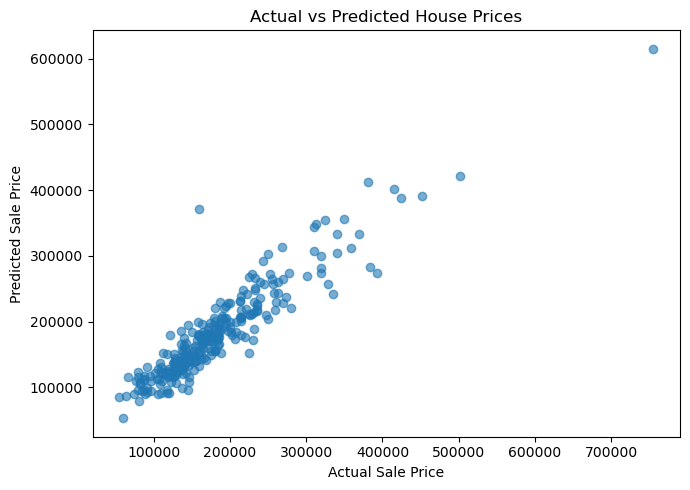

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(y_valid, forest_predictions, alpha=0.6)
plt.xlabel('Actual Sale Price')
plt.ylabel('Predicted Sale Price')
plt.title('Actual vs Predicted House Prices')
plt.tight_layout()
plt.show()


## Conclusion

Random Forest outperformed Decision Tree with a lower MAE of $19,803.99 and a higher R² score of 0.860.

Therefore, Random Forest was selected as the better model for house price prediction.
